# Electrode-pair polarity check, 2-fish ground truth (2024-02-13T14_33_21)

The same mirror-symmetry test as `electrode_polarity_check.ipynb` (4-fish recordings of 2024-02-20, where pairs 2 and 5 came out
reversed), on the 2-fish recording of `data/2_fish_silent`, in which **only fish 1 (the larger fish) emits**: every EOD is the
larger fish's, so no step has to decide who emitted.

**Logic.** Neighbouring pairs a and b along the tank wall have one electrode each at a shared spot (a tank corner, or the middle
of a wall). The line that mirrors pair a onto pair b runs through that spot. When the emitting fish lies on this line with
one end at the spot, the whole scene is mirror-symmetric, so the two pairs see the same potential difference up to their labels:

* the two electrodes at the spot carry the **same** label (both − or both +) → the two pair voltages have the **same** sign;
* **different** labels → **opposite** signs.

This compares two pairs within one EOD, so the unknown sign of the EOD cancels. A pair with swapped wiring breaks the rule at every
spot it shares with a correctly wired neighbour. Nothing is fitted and no recorded sign is changed. The model is only an
illustration in the example plots (it obeys the symmetry with the CSV labels by construction).

**Selection**, unchanged from the 4-fish notebook (same functions and thresholds): the larger fish with its head or tail near the
spot, its axis and its head, middle and tail keypoints close to the mirror line, no other fish near the spot; the two pairs are the
two largest of the EOD's pattern; then from the masks: body within a narrow band around the line, extent along the line ≥ 85% of
its length, the other fish's body ≥ `CLEAR_MIN` away.

**Data:** EODs `Data_1fish_2024-02-13T14_33_21.csv` (50 kHz, 25 samples), ZEUS masks
(`elephantnose_20240213T143321_tracking_final.pkl`, label 1 = larger fish), electrode file
`data/electrodes_signed_px_coord_2024-02-13.csv` (original labels). Keypoints: Denis' tracked fish A (larger, on mask 1 in every
frame checked) and B, from his `Assigned_Data_1fish_*.csv` (same rows as the EOD table); the EOD table's own `_1/_2` keypoint
identities do not follow the fish, so they are not used.

In [1]:
import re
import pickle
import mask_metrics as mm                         # ZEUS crop unpacking (sets the Agg backend...)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
from scipy.ndimage import distance_transform_edt
from compute_electric_field import mask_to_grid
from eod_assign import (load_electrode_pairs, eod_sample_count, eods_with_masks, recorded_pair_traces_all,
                        recorded_pair_traces, eod_phase_samples, normalize_peak, candidate_field, pair_voltages,
                        iter_mgz_frames)
from midline_methods import fish_midline_with_head
from io_utils import rle_decode

ELECTRODES_CSV = 'data/electrodes_signed_px_coord_2024-02-13.csv'
P, FS = 912, 50000.0                            # 2-fish recording: 50 kHz
N, delta_h = 200, 0.5
MAT = dict(sigma_water=1.0, eps_water=0.0, sigma_interior=200.0, eps_interior=0.0, sigma_skin=0.05, eps_skin=2.7e-6)

pairs = load_electrode_pairs(ELECTRODES_CSV, P)
pair_ids = [pid for pid, _, _ in pairs]

def mask_under_keypoint(row, fm, k):
    '''Index of the mask nearest tracked fish k's middle keypoint in a df_eod row (the mask under it, if any).'''
    p = np.array([row[f'middle_y_{k}'], row[f'middle_x_{k}']])
    return int(np.argmin([np.min(np.linalg.norm(np.argwhere(m) - p, axis=1)) if m.any() else np.inf for m in fm]))

def load_recording(name, eod_csv, n_frames, frame_masks, mask_of=mask_under_keypoint):
    '''One recording: its EODs, their rank-1 patterns and the tracked keypoints.
       frame_masks(frames) -> {frame: (n_fish, P, P) masks}; mask_of(row, frame masks, fish id) -> index of that fish's mask.'''
    df_all = eod_csv if isinstance(eod_csv, pd.DataFrame) else pd.read_csv(eod_csv, low_memory=False)
    df = eods_with_masks(df_all, n_frames)
    n_samp = eod_sample_count(df)
    V_all = recorded_pair_traces_all(df, pair_ids, n_samp)
    U_, s_, _ = np.linalg.svd(np.nan_to_num(V_all), full_matrices=False)
    ids = sorted(m.group(1) for c in df.columns for m in [re.match(r'middle_x_(\w+)$', c)] if m)
    kp = {k: [df[[f'{b}_y_{k}', f'{b}_x_{k}']].to_numpy(float) / (P - 1) for b in ('head', 'middle', 'tail')] for k in ids}
    lengths = {k: np.nanmedian(np.linalg.norm(kp[k][0] - kp[k][2], axis=1)) * (P - 1) for k in ids}
    R = dict(name=name, df=df, n_samp=n_samp, u=U_[:, :, 0] * s_[:, :1], ids=ids, kp=kp, lengths=lengths,
             big=max(lengths, key=lengths.get), frame_masks=frame_masks, mask_of=mask_of)
    print(f"{name}: {len(df)} EODs | variance in the rank-1 pattern: median "
          f"{np.median(s_[:, 0]**2 / np.sum(s_**2, axis=1)):.4f} | median head-tail length per tracked fish (px): "
          f"{ {k: round(v) for k, v in lengths.items()} } -> largest: {R['big']}")
    return R

## 1. Mirror lines and the shared spots

The mirror line of pairs a and b is the perpendicular bisector of the two pairs' midpoints (reflecting across it maps one pair
onto the other). For the corner pairs 2/3 (and 4/5) it runs along the tank diagonal. Pairs 5 and 6 lie on the same wall
with their − ends meeting in the middle of it, so their mirror line is perpendicular to that wall.

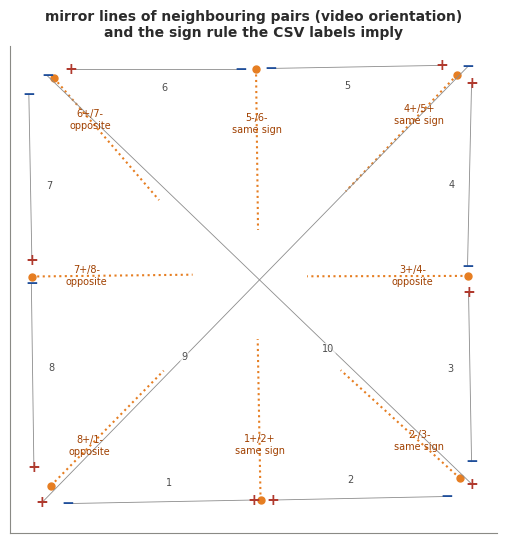

In [2]:
SPOTS = [(1, 2), (2, 3), (3, 4), (4, 5), (5, 6), (6, 7), (7, 8), (8, 1)]
ELEC = {pid: {'+': pp, '-': pm} for pid, pp, pm in pairs}

def mirror_line(pa, pb):
    '''(spot, d, labels): the point of the mirror line of pairs pa, pb next to their closest electrodes, the line's unit
       direction pointing into the tank, and the labels (of pa, of pb) of those two closest electrodes. Tank coordinates.'''
    la, lb = min(((x, y) for x in '+-' for y in '+-'), key=lambda xy: np.linalg.norm(ELEC[pa][xy[0]] - ELEC[pb][xy[1]]))
    ma, mb = 0.5 * (ELEC[pa]['+'] + ELEC[pa]['-']), 0.5 * (ELEC[pb]['+'] + ELEC[pb]['-'])
    n = (mb - ma) / np.linalg.norm(mb - ma)
    d = np.array([-n[1], n[0]]); c = 0.5 * (ma + mb)
    spot = c + ((0.5 * (ELEC[pa][la] + ELEC[pb][lb]) - c) @ d) * d
    if (0.5 - spot) @ d < 0: d = -d
    return spot, d, (la, lb)

def draw_electrodes(ax, highlight=(), colors=None):
    '''Electrodes in video orientation (x = pixel column, y = pixel row downwards).'''
    for q, pp, pm in pairs:
        hl = q in highlight; c = (colors or {}).get(q, 'm')
        ax.plot([pp[1], pm[1]], [pp[0], pm[0]], color=c if hl else '0.55', lw=2.2 if hl else 0.6, zorder=3)
        ax.text(pp[1], pp[0], '+', color='#B03A2E', fontsize=15 if hl else 11, weight='bold', ha='center', va='center', zorder=4)
        ax.text(pm[1], pm[0], '−', color='#1F4E9A', fontsize=15 if hl else 11, weight='bold', ha='center', va='center', zorder=4)
        mid = 0.5 * (pp + pm) if np.linalg.norm(pp - pm) < 1 else pp + 0.3 * (pm - pp)
        lab = mid + 0.045 * (0.5 - mid) / max(np.linalg.norm(0.5 - mid), 1e-9)
        ax.text(lab[1], lab[0], str(q), zorder=6, bbox=dict(boxstyle='round,pad=0.1', fc='w', ec='none', alpha=0.7),
                fontsize=10 if hl else 7, color=c if hl else '0.3', weight='bold' if hl else 'normal', ha='center', va='center')
    ax.set(xlim=(-0.03, 1.03), ylim=(1.03, -0.03), aspect='equal', xticks=[], yticks=[])

fig, ax = plt.subplots(figsize=(5.5, 5.5))
draw_electrodes(ax)
for pa, pb in SPOTS:
    spot, d, (la, lb) = mirror_line(pa, pb)
    end = spot + 0.35 * d
    ax.plot([spot[1], end[1]], [spot[0], end[0]], ':', color='#E67E22', lw=1.5)
    ax.plot(spot[1], spot[0], 'o', color='#E67E22', ms=5)
    t = spot + 0.12 * d
    ax.text(t[1], t[0], f'{pa}{la}/{pb}{lb}\n' + ('same sign' if la == lb else 'opposite'), fontsize=7, ha='center',
            va='center', color='#A04000')
ax.set_title('mirror lines of neighbouring pairs (video orientation)\nand the sign rule the CSV labels imply', fontsize=10)
plt.tight_layout(); plt.show()

### The search and the plots

Thresholds, in tank units (1 = 911 px): the fish's end within 0.18 of the spot, axis within 30° of the line, keypoints within
0.06 of it, other fish at least 0.2 away; then the mask: 98th percentile of the pixels' distance from the line ≤ `BAND_MAX`,
extent along the line ≥ `EXTENT_MIN` × the fish's median head–tail length, and every other fish's mask at least `CLEAR_MIN`
from the emitter's mask. Only the frames that pass the keypoint step are
read from the masks.

Examples: two frames per spot, both of the largest fish, from two separate visits to the spot (at least 100 frames apart),
favouring the EODs with the other fish farthest away (score: band + distance of the fish's end from the spot + angle to the
line − distance to the nearest other fish). The 5/6 spot is busy: there the nearest other fish is never much more than 100–
160 px away. Each row:
the model potential with the fish (video orientation, emitter outlined thick), the recorded traces of all 10 pairs, and model
vs recording at the EOD's first phase P1, each scaled to max |v| = 1. No sign is changed anywhere.

In [3]:
BAND_MAX, EXTENT_MIN, CLEAR_MIN = 0.05, 0.85, 0.10      # CLEAR_MIN: 91 px, about half the largest fish
EV_COLS = ['pa', 'pb', 'row', 'frame', 'k', 'end', 'dist_end', 'angle', 'offset', 'other', 'u_a', 'u_b', 'same_sign', 'rule_same']
PAIR_COLORS = ('m', '#16A085')
g = np.linspace(0, 1, N)

def symmetric_events(R, pa, pb, max_end=0.18, max_angle=30.0, max_offset=0.06, min_other=0.2):
    '''EODs of recording R passing selection steps 1-3 for the spot of pairs pa, pb, with the largest fish at the spot.'''
    df, u, kp, k = R['df'], R['u'], R['kp'], R['big']
    spot, d, (la, lb) = mirror_line(pa, pb); nrm = np.array([-d[1], d[0]])
    ia, ib = pair_ids.index(pa), pair_ids.index(pb)
    top2 = np.sort(np.argsort(-np.abs(u), axis=1)[:, :2], axis=1)
    is_top = (top2 == sorted((ia, ib))).all(axis=1)
    H, Mid, T = kp[k]
    dH, dT = np.linalg.norm(H - spot, axis=1), np.linalg.norm(T - spot, axis=1)
    head_in = dH < dT
    E, O = np.where(head_in[:, None], H, T), np.where(head_in[:, None], T, H)
    axis = (O - E) / np.linalg.norm(O - E, axis=1, keepdims=True)
    angle = np.degrees(np.arccos(np.clip(axis @ d, -1, 1)))
    offset = np.max([np.abs((q - spot) @ nrm) for q in (H, Mid, T)], axis=0)
    other = np.nanmin([np.linalg.norm(q - spot, axis=1) for j in R['ids'] if j != k for q in kp[j]], axis=0)
    with np.errstate(invalid='ignore'):
        ok = is_top & (np.minimum(dH, dT) < max_end) & (angle < max_angle) & (offset < max_offset) & (other > min_other)
    return pd.DataFrame([dict(pa=pa, pb=pb, row=df.index[i], frame=int(df['Frame'].iloc[i]), k=k,
                              end='head' if head_in[i] else 'tail', dist_end=min(dH[i], dT[i]), angle=angle[i],
                              offset=offset[i], other=other[i], u_a=u[i, ia], u_b=u[i, ib],
                              same_sign=bool(np.sign(u[i, ia]) == np.sign(u[i, ib])), rule_same=la == lb)
                         for i in np.flatnonzero(ok)], columns=EV_COLS)

def along_line(mask, spot, d):
    '''(band, extent) of a mask relative to the line (spot, d): 98th percentile of its pixels' distance from the line, and
       its extent along the line (1st to 99th percentile). Tank units.'''
    q = np.argwhere(mask) / (P - 1) - spot
    s = q @ d
    return np.percentile(np.abs(q @ np.array([-d[1], d[0]])), 98), np.percentile(s, 99) - np.percentile(s, 1)

def mirror_events(R):
    '''All spots: keypoint steps, then the mask step. Returns (all keypoint-step events, events passing the mask step).'''
    ev = pd.concat([symmetric_events(R, pa, pb) for pa, pb in SPOTS], ignore_index=True)
    ev = ev.reindex(columns=EV_COLS + ['mask', 'band', 'extent', 'largest', 'clearance', 'follows_labels'])
    if ev.empty: return ev, ev
    band, extent, largest, mask, clear = {}, {}, {}, {}, {}
    for fr, fm in R['frame_masks'](set(ev.frame)).items():
        for i in ev.index[ev.frame == fr]:
            f = mask[i] = R['mask_of'](R['df'].loc[int(ev.at[i, 'row'])], fm, R['big'])
            spot, d, _ = mirror_line(int(ev.at[i, 'pa']), int(ev.at[i, 'pb']))
            largest[i] = f == int(np.argmax([m.sum() for m in fm]))
            band[i], extent[i] = along_line(fm[f], spot, d) if fm[f].any() else (np.nan, np.nan)
            extent[i] /= R['lengths'][R['big']] / (P - 1)
            dt = distance_transform_edt(~fm[f])
            clear[i] = min((dt[m].min() for j, m in enumerate(fm) if j != f and m.any()), default=np.inf) / (P - 1)
    ev['mask'], ev['band'], ev['extent'], ev['largest'] = pd.Series(mask), pd.Series(band), pd.Series(extent), pd.Series(largest)
    ev['clearance'] = pd.Series(clear)
    ev['follows_labels'] = ev.same_sign == ev.rule_same
    return ev, ev[(ev.band <= BAND_MAX) & (ev.extent >= EXTENT_MIN) & (ev.clearance >= CLEAR_MIN)]

def spot_table(E):
    idx = pd.MultiIndex.from_tuples(SPOTS, names=['pa', 'pb'])
    lab = {s: mirror_line(*s)[2] for s in SPOTS}
    t = pd.DataFrame({'labels at spot': [f'{a}{lab[(a, b)][0]} / {b}{lab[(a, b)][1]}' for a, b in SPOTS],
                      'rule': ['same sign' if lab[s][0] == lab[s][1] else 'opposite' for s in SPOTS]}, index=idx)
    g_ = E.groupby(['pa', 'pb']) if len(E) else None
    t['EODs'] = (g_.size().reindex(idx) if g_ else pd.Series(0, idx)).fillna(0).astype(int)
    t['visits (>100 frames apart)'] = (g_.frame.apply(lambda f: int((np.diff(np.sort(f.to_numpy())) > 100).sum() + 1))
                                       .reindex(idx) if g_ else pd.Series(0, idx)).fillna(0).astype(int)
    t['follow labels'] = (g_.follows_labels.mean().reindex(idx) if g_ else pd.Series(np.nan, idx)).round(2)
    t['verdict'] = ['no symmetric fish' if n == 0 else ('labels hold' if m >= 0.9 else
                    ('labels CONTRADICTED' if m <= 0.1 else 'mixed')) for n, m in zip(t.EODs, t['follow labels'])]
    return t

def pick_examples(sym, pa, pb, n=2, min_gap=100):
    E = sym[(sym.pa == pa) & (sym.pb == pb)].assign(score=lambda x: x.band + x.dist_end + x.angle / 100 - x.clearance)
    out = []
    for _, e in E.sort_values('score').iterrows():
        if len(out) == n: break
        if all(abs(e.frame - o.frame) > min_gap for o in out): out.append(e)
    return out

def head_agrees(row, k, mid):
    '''Whether the midline's head end is nearer the row's head keypoint of fish k than its tail end is.'''
    hd = np.array([row[f'head_y_{k}'], row[f'head_x_{k}']]) / (P - 1)
    tl = np.array([row[f'tail_y_{k}'], row[f'tail_x_{k}']]) / (P - 1)
    return bool(np.linalg.norm(mid[-1] - hd) + np.linalg.norm(mid[0] - tl) < np.linalg.norm(mid[-1] - tl) + np.linalg.norm(mid[0] - hd))

def plot_example(axes, R, e, fm):
    pa, pb = int(e.pa), int(e.pb); r = int(e.row); row = R['df'].loc[r]
    f = int(e['mask']); colors = dict(zip((pa, pb), PAIR_COLORS))
    mids = [fish_midline_with_head(m, n_ctrl=101)['midline'] if m.sum() >= 50 else None for m in fm]
    phi = candidate_field(fm, f, mids[f], N, delta_h, MAT).real
    a = normalize_peak(pair_voltages(phi, pairs, N))
    V = recorded_pair_traces(row, pair_ids, R['n_samp'])
    p1, p2 = eod_phase_samples(V)
    b = normalize_peak(V[:, p1])
    ia, ib = pair_ids.index(pa), pair_ids.index(pb)
    spot, d, _ = mirror_line(pa, pb)
    t_ms = np.arange(R['n_samp']) / FS * 1e3

    ax = axes[0]
    vmax = np.percentile(np.abs(phi), 99)
    ax.imshow(phi, origin='upper', extent=[0, 1, 1, 0], cmap='RdBu_r', vmin=-vmax, vmax=vmax)
    for j, m in enumerate(fm):
        if m.any():
            ax.contour(g, g, mask_to_grid(m, N).astype(float), levels=[0.5], colors=['k' if j == f else '0.35'],
                       linewidths=2.0 if j == f else 0.8)
    ax.plot(mids[f][-1][1], mids[f][-1][0], 'o', color='gold', ms=7, mec='k', mew=0.8, zorder=5, label='head')
    ax.plot(mids[f][0][1], mids[f][0][0], 's', color='w', ms=6, mec='k', mew=0.8, zorder=5, label='tail')
    end = spot + 0.45 * d
    ax.plot([spot[1], end[1]], [spot[0], end[0]], ':', color='k', lw=1, zorder=3, label=f'{pa}/{pb} mirror line')
    draw_electrodes(ax, (pa, pb), colors)
    big = 'largest fish' if e.largest else 'largest fish (not the largest mask in this frame)'
    ax.set_title(f'frame {int(e.frame)}: {big} ({R["big"]}), {e.end} at the {pa}/{pb} spot\n'
                 f'body within {e.band * (P - 1):.0f} px of the line, nearest other fish {e.clearance * (P - 1):.0f} px; '
                 f'model, head-positive current', fontsize=9)
    ax.legend(loc='center', fontsize=7, framealpha=0.8)

    ax = axes[1]
    for i, q in enumerate(pair_ids):
        hl = q in colors
        ax.plot(t_ms, V[i] / np.max(np.abs(V)), color=colors.get(q, '0.75'), lw=2.2 if hl else 0.9,
                label=f'pair {q}' if hl else ('other pairs' if i == 0 else None), zorder=3 if hl else 2)
    for p, lab in ((p1, 'P1'), (p2, 'P2')):
        ax.axvline(t_ms[p], color='k', ls='--' if lab == 'P1' else ':', lw=0.8); ax.text(t_ms[p], 1.08, lab, ha='center', fontsize=9)
    ax.axhline(0, color='0.85', lw=0.5)
    ax.set(xlabel='time (ms)', ylabel='recorded voltage (max |V| = 1)', ylim=(-1.15, 1.2), title=f'recorded EOD (df_eod row {r})')
    ax.legend(fontsize=8, loc='lower left')

    ax = axes[2]
    x = np.arange(len(pair_ids)); w = 0.38
    ax.bar(x - w / 2, b, w, color='k', label=f'recorded at P1 (t = {t_ms[p1]:.2f} ms)')
    ax.bar(x + w / 2, a, w, color='#E67E22', label='model (head-positive current)')
    for q, c in colors.items():
        ax.axvspan(pair_ids.index(q) - 0.5, pair_ids.index(q) + 0.5, color=c, alpha=0.12, zorder=0)
    ax.axhline(0, color='k', lw=0.5)
    ax.set(xticks=x, xticklabels=pair_ids, xlabel='electrode pair', ylabel='voltage (max |v| = 1)', ylim=(-1.25, 1.25),
           title=f'pairs {pa} / {pb}: recorded {b[ia]:+.2f} / {b[ib]:+.2f},  model {a[ia]:+.2f} / {a[ib]:+.2f}')
    ax.legend(fontsize=8, loc='lower left')
    return dict(recording=R['name'], row=r, frame=int(e.frame), pairs=f'{pa}/{pb}', fish=R['big'], end=e.end,
                head_matches_keypoints=head_agrees(row, R['big'], mids[f]),
                rec_a=round(b[ia], 2), rec_b=round(b[ib], 2), model_a=round(a[ia], 2), model_b=round(a[ib], 2))

def show_spot(R, sym, pa, pb, title):
    ex = pick_examples(sym, pa, pb)
    if not ex:
        print(f'{R["name"]}, pairs {pa}/{pb}: no symmetric EOD of the largest fish'); return []
    fms = R['frame_masks']({int(e.frame) for e in ex})
    fig, axes = plt.subplots(len(ex), 3, figsize=(17, 5.6 * len(ex)), squeeze=False,
                             gridspec_kw=dict(width_ratios=[1, 1.1, 1.3]))
    out = [plot_example(ax_row, R, e, fms[int(e.frame)]) for e, ax_row in zip(ex, axes)]
    fig.suptitle(f'{R["name"]}: {title} (largest fish, {len(ex)} visit{"s" if len(ex) > 1 else ""})', fontsize=12)
    plt.tight_layout(rect=[0, 0, 1, 0.95]); plt.show()
    return out

TITLE_23 = 'fish on the 2/3 mirror line (tank diagonal): 2− and 3− share the corner, so pairs 2 and 3 must have the same sign'
TITLE_56 = 'fish on the 5/6 mirror line (perpendicular to the wall): 5− and 6− meet mid-wall, so pairs 5 and 6 must have the same sign'
shown = []

## 2. Recording 2024-02-13T14_33_21 (2 fish, fish 1 emits): symmetric EODs at every spot

In [4]:
DATA = 'data/2_fish_silent'
EOD_CSV = f'{DATA}/Data_1fish_2024-02-13T14_33_21.csv'
DENIS_CSV = 'results/eod_assignment_2_fish_silent/Assigned_Data_1fish_2024-02-13T14_33_21.csv'
TRACK_PKL = f'{DATA}/elephantnose_20240213T143321_tracking_final.pkl'

eod = pd.read_csv(EOD_CSV)
own_kp = [c for c in eod.columns if re.match(r'.+_[xy]_[12]$|score_.+_[12]$', c)]           # the table's _1/_2 keypoints
kp = pd.read_csv(DENIS_CSV, usecols=lambda c: re.match(r'(head|middle|tail)_[xy]_[AB]$', c) is not None)
den_frame = pd.read_csv(DENIS_CSV, usecols=['Frame']).Frame
assert len(kp) == len(eod) and (den_frame.to_numpy() == eod.Frame.to_numpy()).all()       # same rows, same order
eod2 = pd.concat([eod.drop(columns=own_kp), kp], axis=1)

with open(TRACK_PKL, 'rb') as fh:
    trk = pickle.load(fh)
assert trk['shape'][0] == P

def zeus_frame_masks(frames):
    '''{frame: (2, P, P) masks}, index = ZEUS label (0 = smaller fish, 1 = larger fish, the emitter).'''
    out = {}
    for k in sorted(frames):
        fm = np.zeros((2, P, P), bool)
        for l, packed, (y0, y1, x0, x1) in zip(*(trk['frames'][k][c] for c in ('labels', 'masks', 'boxes'))):
            if l in (0, 1): fm[l, y0:y1, x0:x1] = mm.unpack_crop(packed, (y0, y1, x0, x1))
        out[k] = fm
    return out

R3 = load_recording('2024-02-13T14_33_21 (2 fish)', eod2, len(trk['frames']), zeus_frame_masks)
assert R3['big'] == 'A'
ev3, sym3 = mirror_events(R3)
print(f"{len(ev3)} EODs after the keypoint steps, {len(sym3)} after the mask step | emitter on mask 1 (larger fish) in "
      f"{(sym3['mask'] == 1).mean():.0%} of them")
spot_table(sym3)

2024-02-13T14_33_21 (2 fish): 18769 EODs | variance in the rank-1 pattern: median 0.9995 | median head-tail length per tracked fish (px): {'A': 157, 'B': 105} -> largest: A


/var/folders/w4/p225s7cd19n0j6tss7pdl21w0000gn/T/ipykernel_91151/1218731291.py:38: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  ev = pd.concat([symmetric_events(R, pa, pb) for pa, pb in SPOTS], ignore_index=True)


62 EODs after the keypoint steps, 2 after the mask step | emitter on mask 1 (larger fish) in 100% of them


,,labels at spot,rule,EODs,visits (>100 frames apart),follow labels,verdict
pa,pb,,,,,,
1,2,1+ / 2+,same sign,0,0,NaN,no symmetric fish
2,3,2- / 3-,same sign,0,0,NaN,no symmetric fish
3,4,3+ / 4-,opposite,2,1,1.0,labels hold
4,5,4+ / 5+,same sign,0,0,NaN,no symmetric fish
5,6,5- / 6-,same sign,0,0,NaN,no symmetric fish
6,7,6+ / 7-,opposite,0,0,NaN,no symmetric fish
7,8,7+ / 8-,opposite,0,0,NaN,no symmetric fish
8,1,8+ / 1-,opposite,0,0,NaN,no symmetric fish


In [5]:
print('the same table without the mask step (keypoints only):')
spot_table(ev3)

the same table without the mask step (keypoints only):


,,labels at spot,rule,EODs,visits (>100 frames apart),follow labels,verdict
pa,pb,,,,,,
1,2,1+ / 2+,same sign,4,3,1.0,labels hold
2,3,2- / 3-,same sign,1,1,1.0,labels hold
3,4,3+ / 4-,opposite,13,2,1.0,labels hold
4,5,4+ / 5+,same sign,0,0,NaN,no symmetric fish
5,6,5- / 6-,same sign,0,0,NaN,no symmetric fish
6,7,6+ / 7-,opposite,2,1,0.0,labels CONTRADICTED
7,8,7+ / 8-,opposite,32,5,1.0,labels hold
8,1,8+ / 1-,opposite,10,6,0.0,labels CONTRADICTED


### Mask step with a wider band

The ZEUS masks of this recording include the pectoral fins, which stick out 30–40 px from the body, so a fish lying straight on the
mirror line still has 98% of its mask pixels 50–90 px from the line, and the band of the 4-fish notebook (`BAND_MAX` = 0.05, 46 px)
keeps only 2 EODs. Here the band is widened to `BAND_WIDE` = 0.08 (73 px); the extent and clearance conditions and all keypoint steps
are unchanged.

In [6]:
BAND_WIDE = 0.08
sym3w = ev3[(ev3.band <= BAND_WIDE) & (ev3.extent >= EXTENT_MIN) & (ev3.clearance >= CLEAR_MIN)]
print(f"{len(sym3w)} EODs pass the mask step with the band at {BAND_WIDE * (P - 1):.0f} px")
spot_table(sym3w)

30 EODs pass the mask step with the band at 73 px


,,labels at spot,rule,EODs,visits (>100 frames apart),follow labels,verdict
pa,pb,,,,,,
1,2,1+ / 2+,same sign,2,2,1.0,labels hold
2,3,2- / 3-,same sign,0,0,NaN,no symmetric fish
3,4,3+ / 4-,opposite,12,1,1.0,labels hold
4,5,4+ / 5+,same sign,0,0,NaN,no symmetric fish
5,6,5- / 6-,same sign,0,0,NaN,no symmetric fish
6,7,6+ / 7-,opposite,1,1,0.0,labels CONTRADICTED
7,8,7+ / 8-,opposite,9,3,1.0,labels hold
8,1,8+ / 1-,opposite,6,4,0.0,labels CONTRADICTED


## 3. Examples at every spot, with the model

Two frames per spot (two visits at least 100 frames apart) where available, from the EODs passing the wider band, chosen as in
the 4-fish notebook. Each row: the model
potential with the fish (emitter outlined thick, video orientation), the recorded traces of all 10 pairs, and model vs recording at
the EOD's first phase P1, each scaled to max |v| = 1. The model uses the current `multipole_sources` (sink 5% of the body length
from the tail tip) and the electrode labels of the CSV; no sign is changed anywhere.

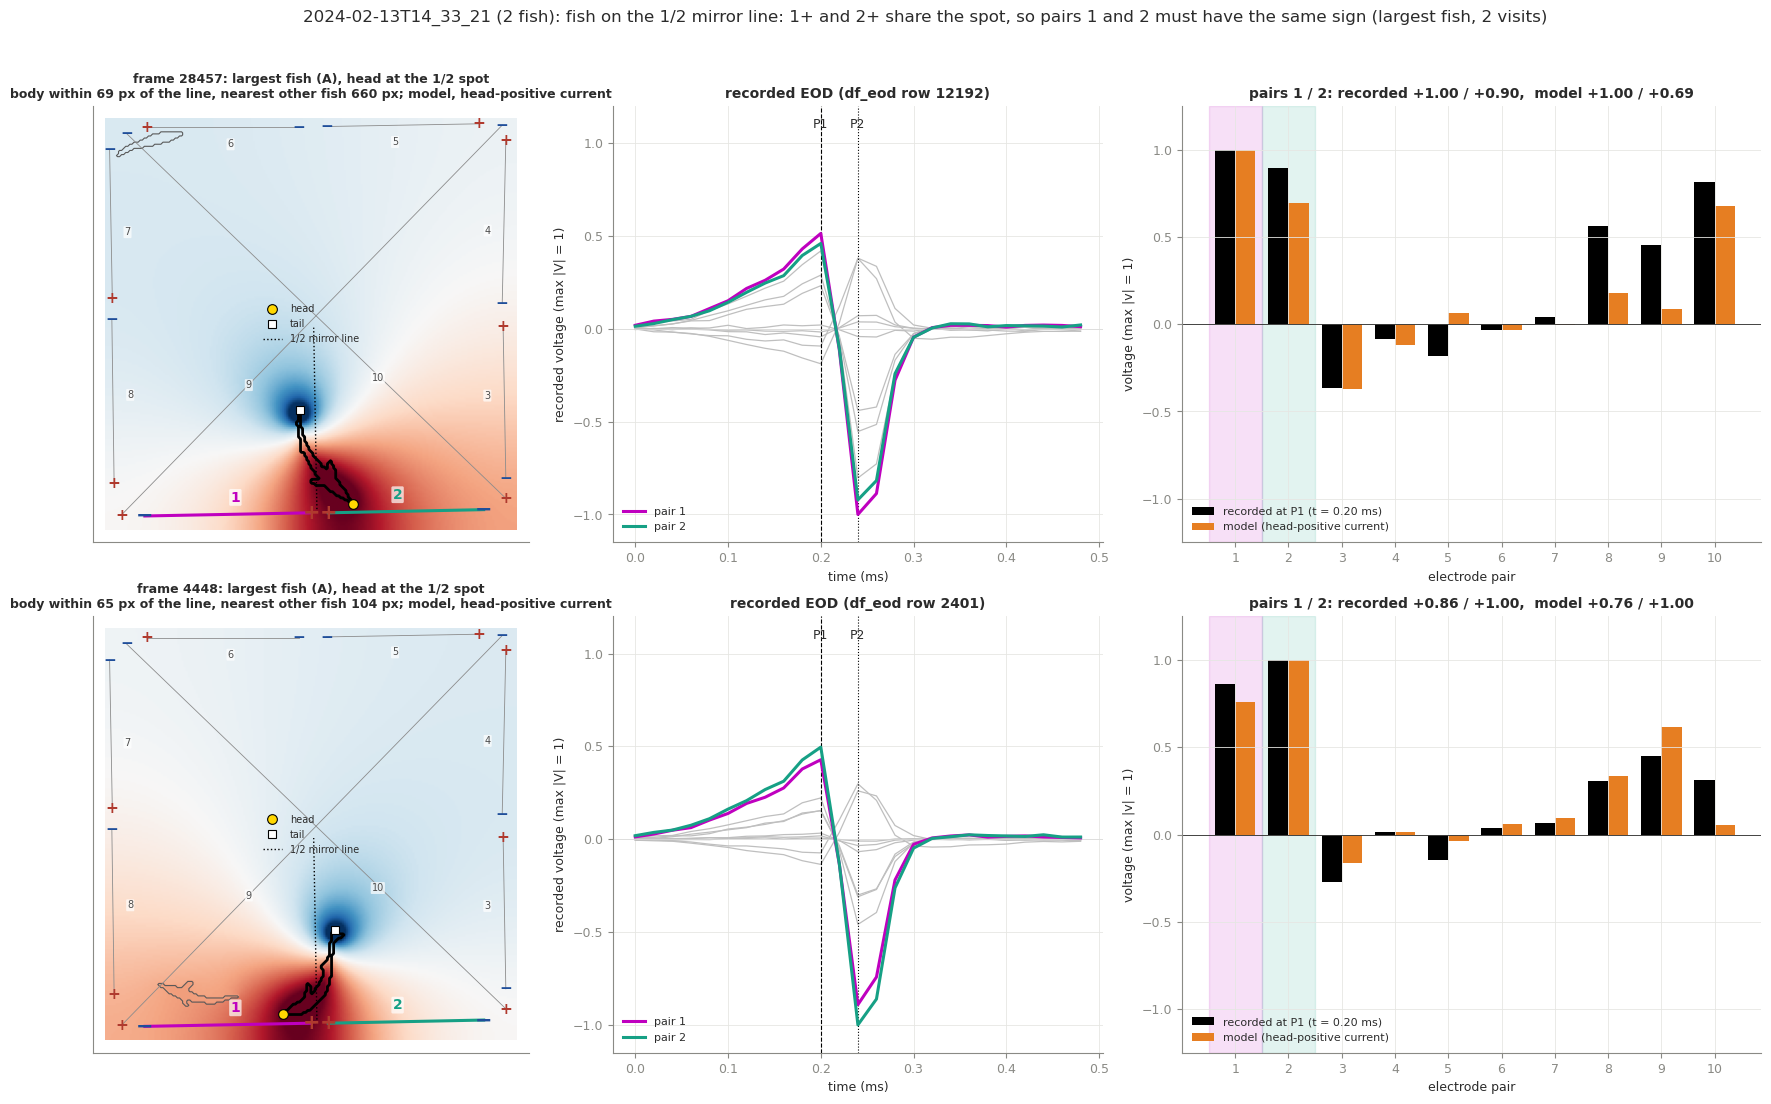

pairs 2/3: no symmetric EOD of the larger fish


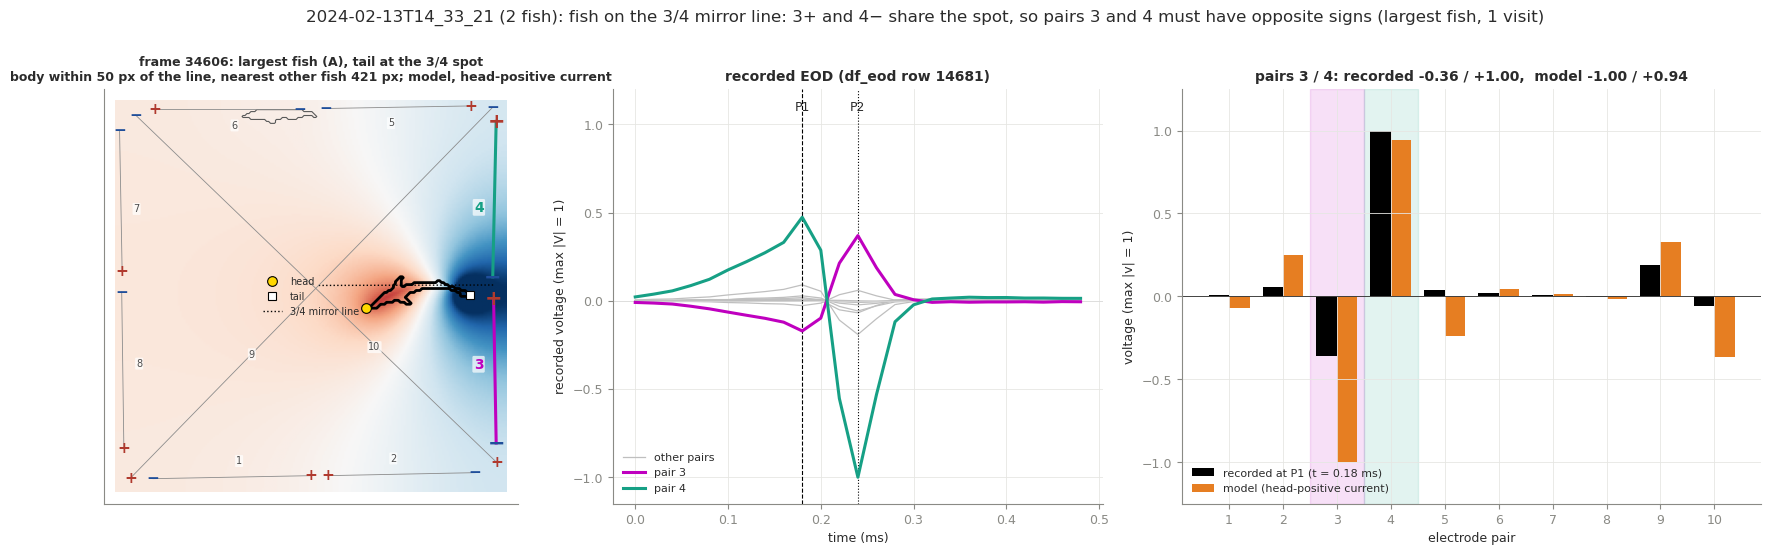

pairs 4/5: no symmetric EOD of the larger fish
pairs 5/6: no symmetric EOD of the larger fish


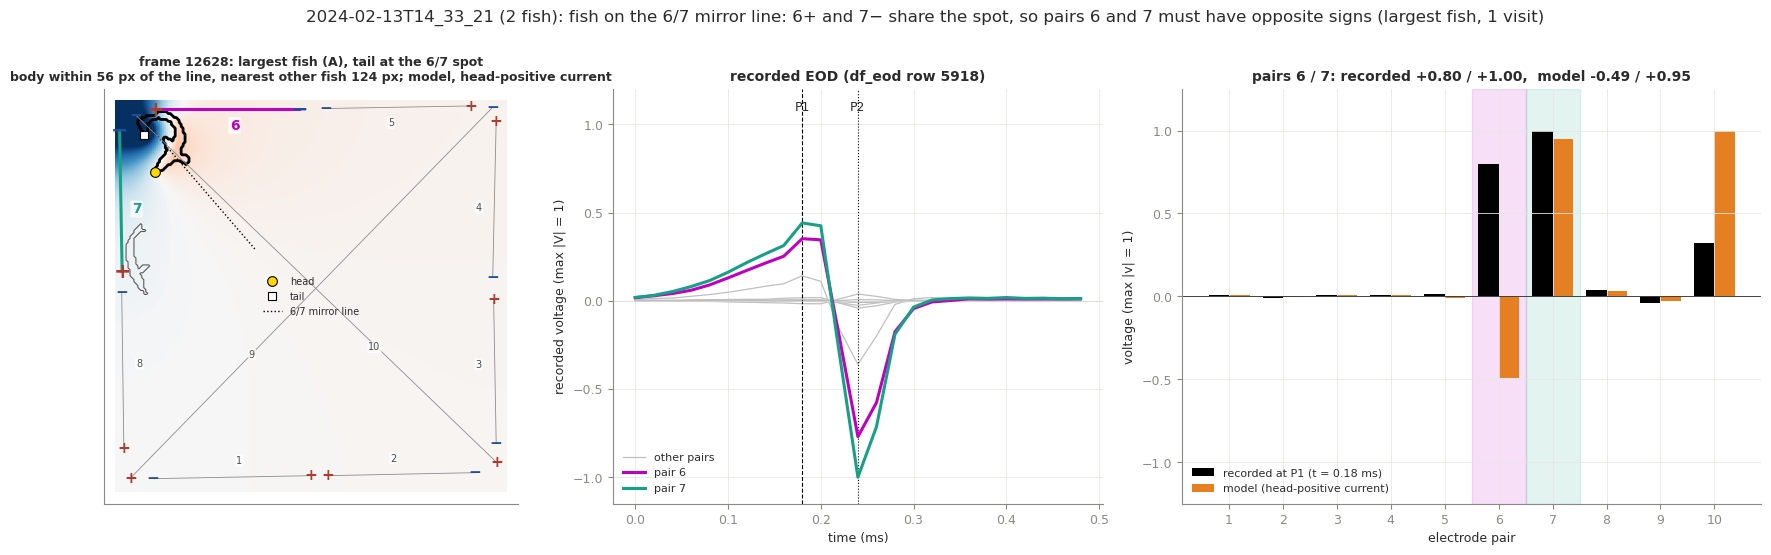

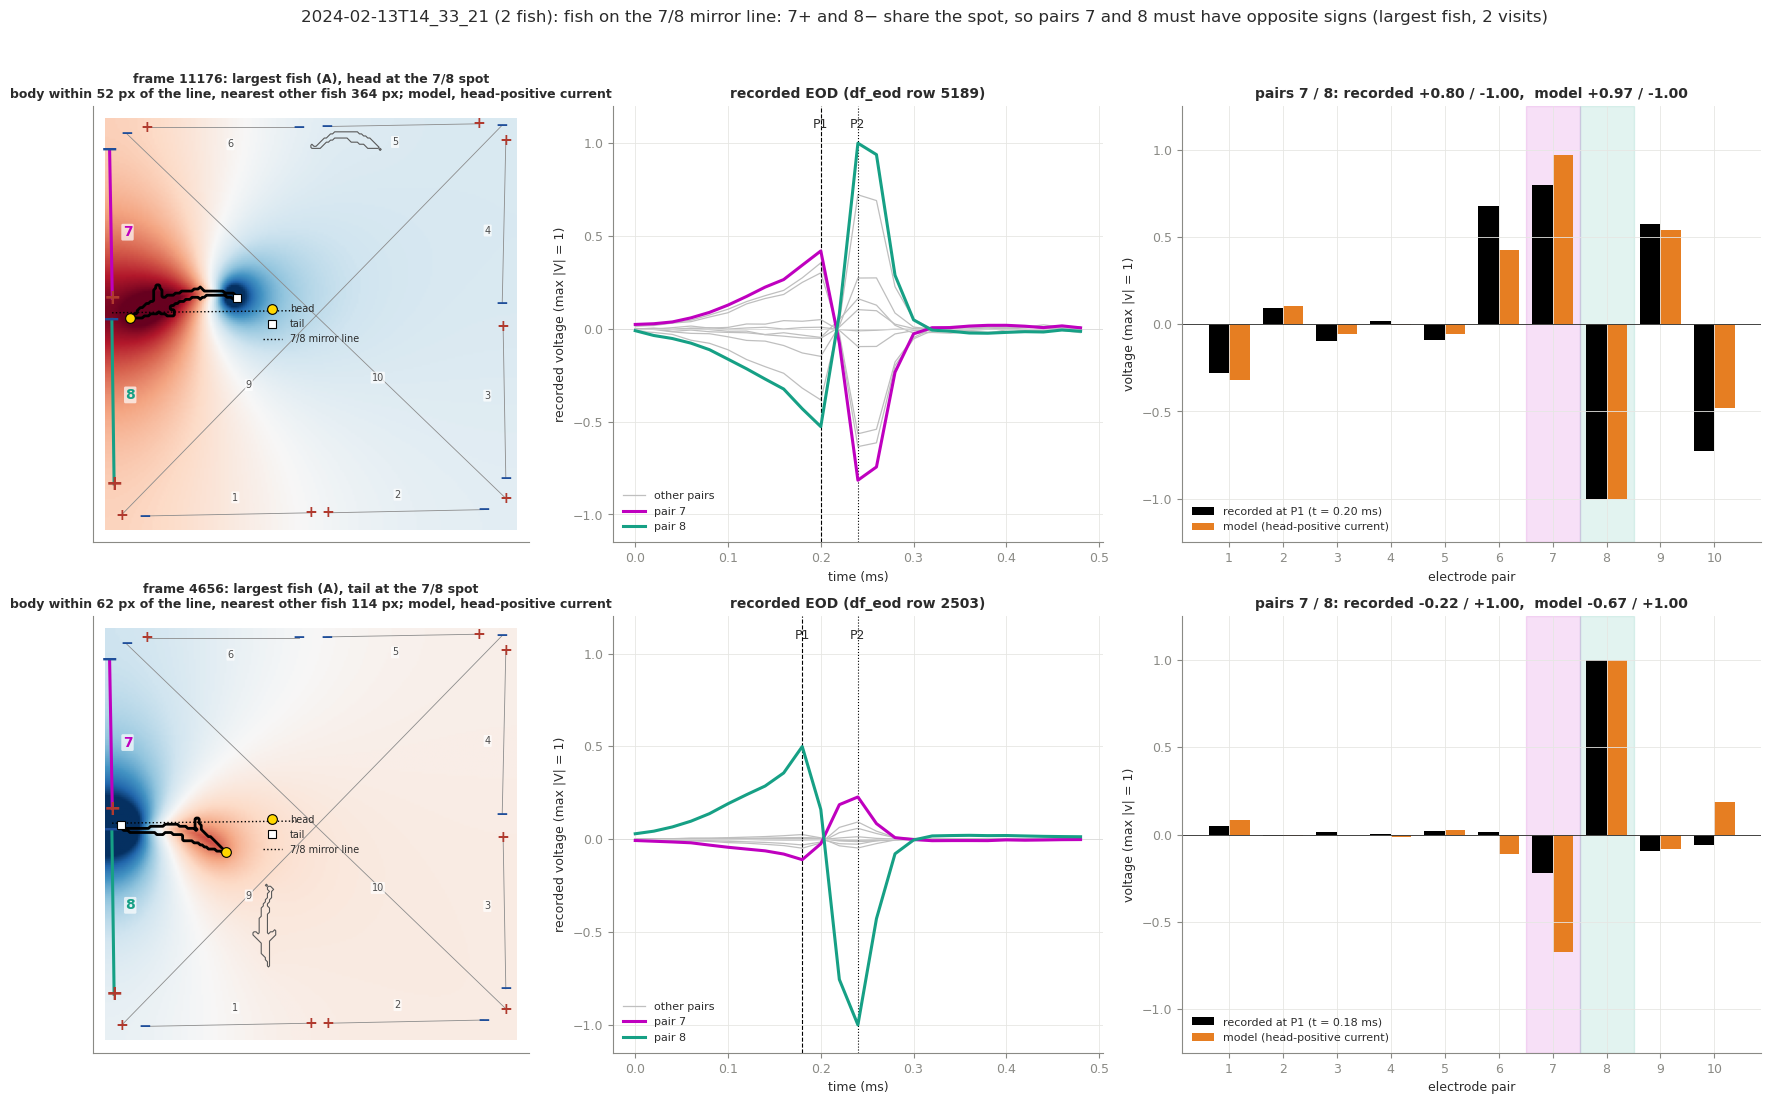

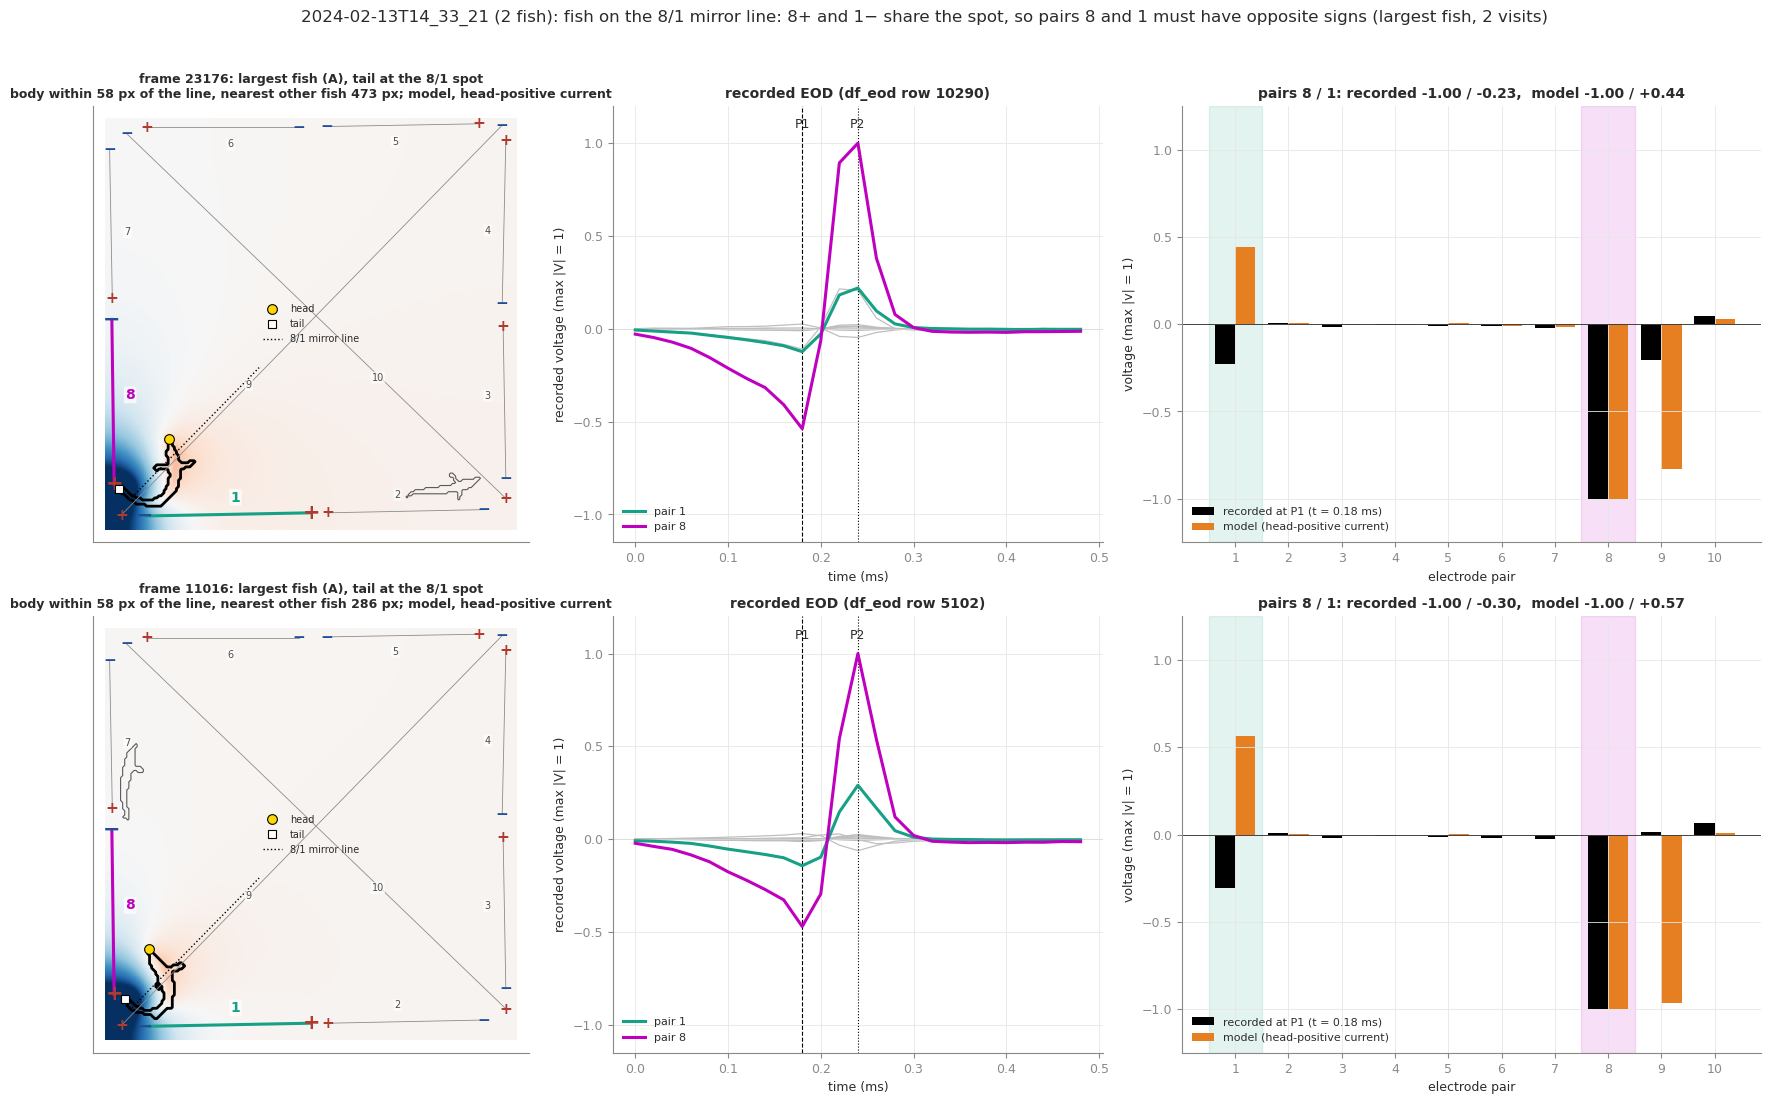

In [7]:
def spot_title(pa, pb):
    la, lb = mirror_line(pa, pb)[2]
    sym = lambda s: s.replace('-', '−')
    return (f'fish on the {pa}/{pb} mirror line: {pa}{sym(la)} and {pb}{sym(lb)} share the spot, so pairs {pa} and {pb} must have '
            + ('the same sign' if la == lb else 'opposite signs'))

shown = []
for pa, pb in SPOTS:
    if ((sym3w.pa == pa) & (sym3w.pb == pb)).any():
        shown += show_spot(R3, sym3w, pa, pb, spot_title(pa, pb))
    else:
        print(f'pairs {pa}/{pb}: no symmetric EOD of the larger fish')

## 4. All example frames

In [8]:
ex = pd.DataFrame(shown)
ex['rule'] = [('same' if mirror_line(*map(int, p.split('/')))[2][0] == mirror_line(*map(int, p.split('/')))[2][1] else 'opposite')
              for p in ex.pairs]
ex['recorded signs'] = np.where(np.sign(ex.rec_a) == np.sign(ex.rec_b), 'same', 'opposite')
ex['follows labels'] = ex['recorded signs'] == ex.rule
ex.to_csv('results/eod_ground_truth/polarity_mirror_2fish_examples.csv', index=False)
display(ex)
pd.concat({'band 46 px (4-fish thresholds)': spot_table(sym3), f'band {BAND_WIDE * (P - 1):.0f} px': spot_table(sym3w),
           'keypoint steps only': spot_table(ev3)}, axis=1).to_csv('results/eod_ground_truth/polarity_mirror_2fish_spots.csv')

,recording,row,frame,pairs,fish,end,head_matches_keypoints,rec_a,rec_b,model_a,model_b,rule,recorded signs,follows labels
0,2024-02-13T14_33_21 (2 fish),12192,28457,1/2,A,head,True,1.00,0.90,1.00,0.69,same,same,True
1,2024-02-13T14_33_21 (2 fish),2401,4448,1/2,A,head,True,0.86,1.00,0.76,1.00,same,same,True
2,2024-02-13T14_33_21 (2 fish),14681,34606,3/4,A,tail,True,-0.36,1.00,-1.00,0.94,opposite,opposite,True
3,2024-02-13T14_33_21 (2 fish),5918,12628,6/7,A,tail,True,0.80,1.00,-0.49,0.95,opposite,same,False
4,2024-02-13T14_33_21 (2 fish),5189,11176,7/8,A,head,True,0.80,-1.00,0.97,-1.00,opposite,opposite,True
5,2024-02-13T14_33_21 (2 fish),2503,4656,7/8,A,tail,True,-0.22,1.00,-0.67,1.00,opposite,opposite,True
6,2024-02-13T14_33_21 (2 fish),10290,23176,8/1,A,tail,True,-1.00,-0.23,-1.00,0.44,opposite,same,False
7,2024-02-13T14_33_21 (2 fish),5102,11016,8/1,A,tail,True,-1.00,-0.30,-1.00,0.57,opposite,same,False
